In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Task 1

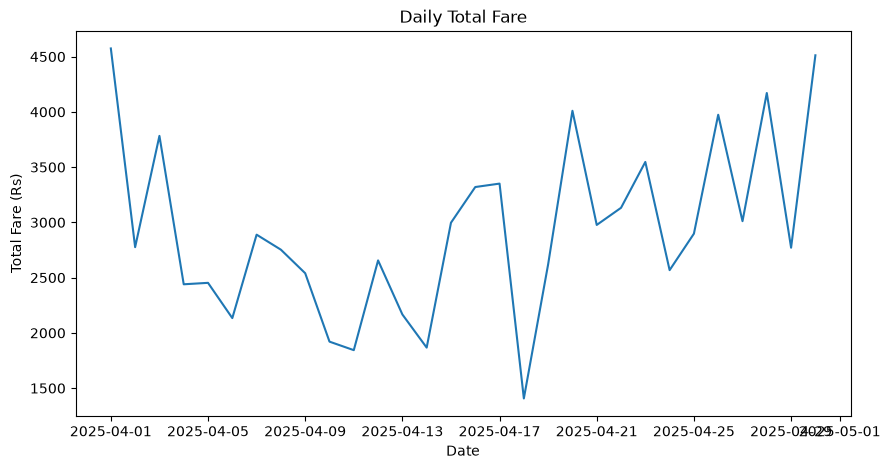

In [2]:
np.random.seed(42)
n = 600

trip_dates = pd.to_datetime('2025-04-01') + pd.to_timedelta(np.random.randint(0, 30, n), unit='D')
distance = np.random.randint(1, 16, n)
noise = np.random.randint(-15, 26, n)

autos = pd.DataFrame({
    'trip_id': range(1, n + 1),
    'trip_date': trip_dates,
    'area': np.random.choice(['Navrangpura', 'Maninagar', 'Satellite', 'Vastrapur', 'Paldi'], n),
    'distance_km': distance,
    'fare_inr': np.round(30 + 14 * distance + noise)
})
autos.to_csv('auto_trips.csv', index=False)

daily_fare = autos.set_index('trip_date')['fare_inr'].resample('D').sum()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(daily_fare.index, daily_fare.values)
ax.set_title('Daily Total Fare')
ax.set_xlabel('Date')
ax.set_ylabel('Total Fare (Rs)')
plt.savefig('daily_fare_line.png')
plt.show()

# Task 2

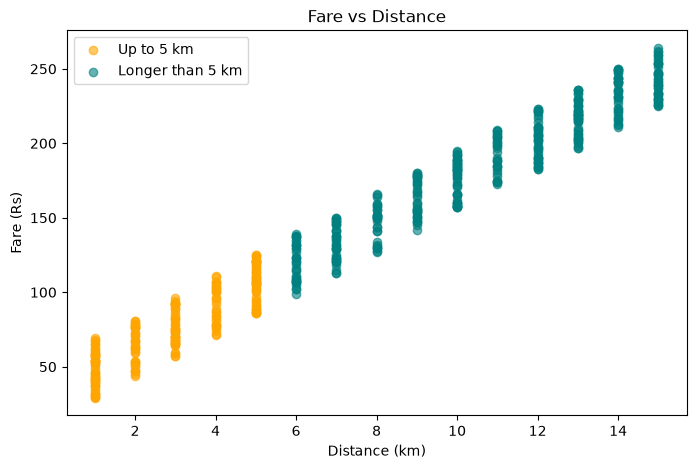

In [3]:
short_trips = autos[autos['distance_km'] <= 5]
long_trips = autos[autos['distance_km'] > 5]

plt.figure(figsize=(8, 5))
plt.scatter(short_trips['distance_km'], short_trips['fare_inr'], color='orange', alpha=0.6, label='Up to 5 km')
plt.scatter(long_trips['distance_km'], long_trips['fare_inr'], color='teal', alpha=0.6, label='Longer than 5 km')
plt.title('Fare vs Distance')
plt.xlabel('Distance (km)')
plt.ylabel('Fare (Rs)')
plt.legend()
plt.savefig('fare_vs_distance.png')
plt.show()

# Task 3

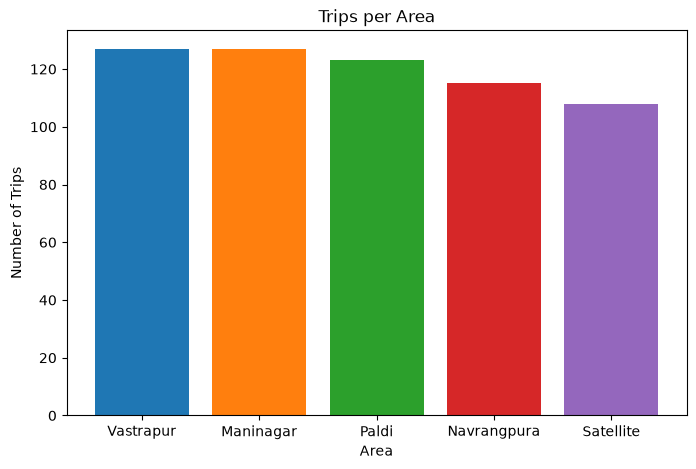

In [4]:
area_counts = autos['area'].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(area_counts.index, area_counts.values, color=['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple'])
ax.set_title('Trips per Area')
ax.set_xlabel('Area')
ax.set_ylabel('Number of Trips')
plt.savefig('trips_per_area.png')
plt.show()

# Task 4

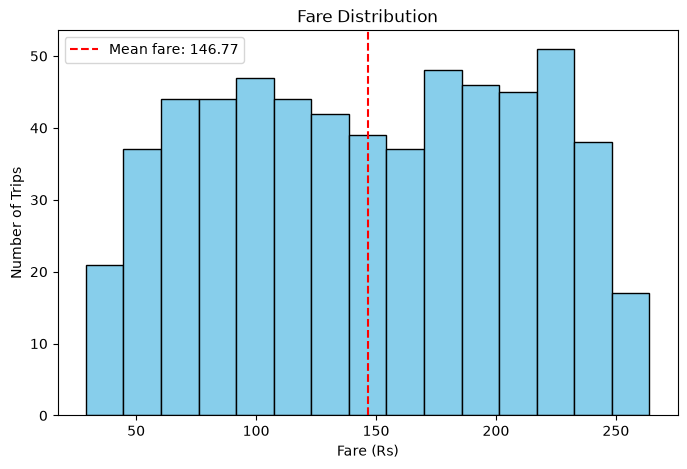

daily_fare_line.png True
fare_vs_distance.png True
trips_per_area.png True
fare_hist.png True


In [5]:
mean_fare = autos['fare_inr'].mean()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(autos['fare_inr'], bins=15, color='skyblue', edgecolor='black')
ax.axvline(mean_fare, color='red', linestyle='--', label='Mean fare: ' + str(round(mean_fare, 2)))
ax.set_title('Fare Distribution')
ax.set_xlabel('Fare (Rs)')
ax.set_ylabel('Number of Trips')
ax.legend()
plt.savefig('fare_hist.png')
plt.show()

png_files = ['daily_fare_line.png', 'fare_vs_distance.png', 'trips_per_area.png', 'fare_hist.png']
for f in png_files:
    print(f, Path(f).exists())
assert all(Path(f).exists() for f in png_files)